<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_Project_feature_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
traditional_features = pd.read_csv("/content/drive/MyDrive/UDA-Project/UDA_final dataset/traditional_features.csv")
shorts_labeled_final = pd.read_csv("/content/drive/MyDrive/UDA-Project/UDA_final dataset/shorts_labeled_final.csv")

# STEP 1. 데이터 불러오기 및 결합

In [ ]:
traditional_features = pd.read_csv(
    "/content/drive/MyDrive/UDA-Project/UDA_final dataset/traditional_features.csv",
    dtype={"video_id": str}
)

shorts_labeled_final = pd.read_csv(
    "/content/drive/MyDrive/UDA-Project/UDA_final dataset/shorts_labeled_final.csv",
    dtype={"video_id": str}
)

# video_id 기준 데이터 결합
trad_eda = shorts_labeled_final.merge(
    traditional_features,
    on="video_id",
    how="inner",
    validate="one_to_one"
)

print("Traditional 특징 데이터:", traditional_features.shape)
print("메타데이터:", shorts_labeled_final.shape)
print("EDA 통합 데이터:", trad_eda.shape)

Traditional 특징 데이터: (1270, 9)
메타데이터: (1270, 28)
EDA 통합 데이터: (1270, 36)


# STEP 2. 분석에 사용할 컬럼 확인

In [ ]:
# Traditional 특징 컬럼
trad_cols = [
    col for col in traditional_features.columns
    if col.startswith("trad_")
]

# 주요 분석 변수
analysis_cols = [
    "video_id",
    "drama_name",
    "channel",
    "duration_sec",
    "days_since_upload",
    "z_in_group",
    "pct_in_group"
] + trad_cols

print("Traditional 특징:", trad_cols)

display(trad_eda[analysis_cols].head())

Traditional 특징: ['trad_brightness_mean', 'trad_brightness_std', 'trad_frame_diff_mean', 'trad_cut_count', 'trad_cut_frequency', 'trad_motion_mean', 'trad_motion_std', 'trad_motion_max']


,video_id,drama_name,channel,duration_sec,days_since_upload,z_in_group,pct_in_group,trad_brightness_mean,trad_brightness_std,trad_frame_diff_mean,trad_cut_count,trad_cut_frequency,trad_motion_mean,trad_motion_std,trad_motion_max
0,NQt0VkR9q_0,김씨 표류기,1분 샤샤샥,46.0,1124.820338,1.764644,1.0,84.801148,21.770071,49.444384,17,0.369565,3.619013,1.797060,8.276316
1,ExRxa0wD3j4,김씨 표류기,1분 샤샤샥,43.0,1123.819551,-0.697115,0.2,99.983671,30.503028,57.218027,18,0.418605,3.405504,1.621436,7.243001
2,86EflpUcel0,김씨 표류기,1분 샤샤샥,20.0,1119.812699,-0.300633,0.6,105.185284,17.596834,49.242087,6,0.300000,3.673920,2.534105,10.236567
3,EN2QjA52vwE,김씨 표류기,1분 샤샤샥,28.0,1117.813012,-0.471814,0.4,87.654302,23.598859,57.663258,18,0.642857,4.157267,1.758647,7.661309
4,GRajxajB8aA,김씨 표류기,1분 샤샤샥,28.0,1116.823348,-0.295083,0.8,77.173350,20.929414,47.973372,13,0.464286,2.978673,1.899618,11.106164


# STEP 3. Traditional 특징의 분포 및 이상치 확인(EDA)

## Traditional 특징 기초 통계 확인

In [ ]:
# Traditional 특징 8개 기초 통계
display(
    trad_eda[trad_cols].describe().T.round(3)
)

,count,mean,std,min,25%,50%,75%,max
trad_brightness_mean,1270.0,57.113,16.788,21.902,44.854,56.490,68.094,115.981
trad_brightness_std,1270.0,11.107,5.499,1.276,7.091,10.073,14.243,37.524
trad_frame_diff_mean,1270.0,23.816,9.085,4.885,17.201,22.361,29.141,57.663
trad_cut_count,1270.0,15.796,12.378,0.000,6.000,14.000,23.000,70.000
trad_cut_frequency,1270.0,0.300,0.195,0.000,0.153,0.288,0.429,0.980
trad_motion_mean,1270.0,1.828,0.582,0.543,1.431,1.772,2.168,4.193
trad_motion_std,1270.0,1.130,0.327,0.429,0.903,1.076,1.292,4.193
trad_motion_max,1270.0,5.533,2.032,1.590,4.200,5.157,6.404,24.182


## 특징 분포 시각화

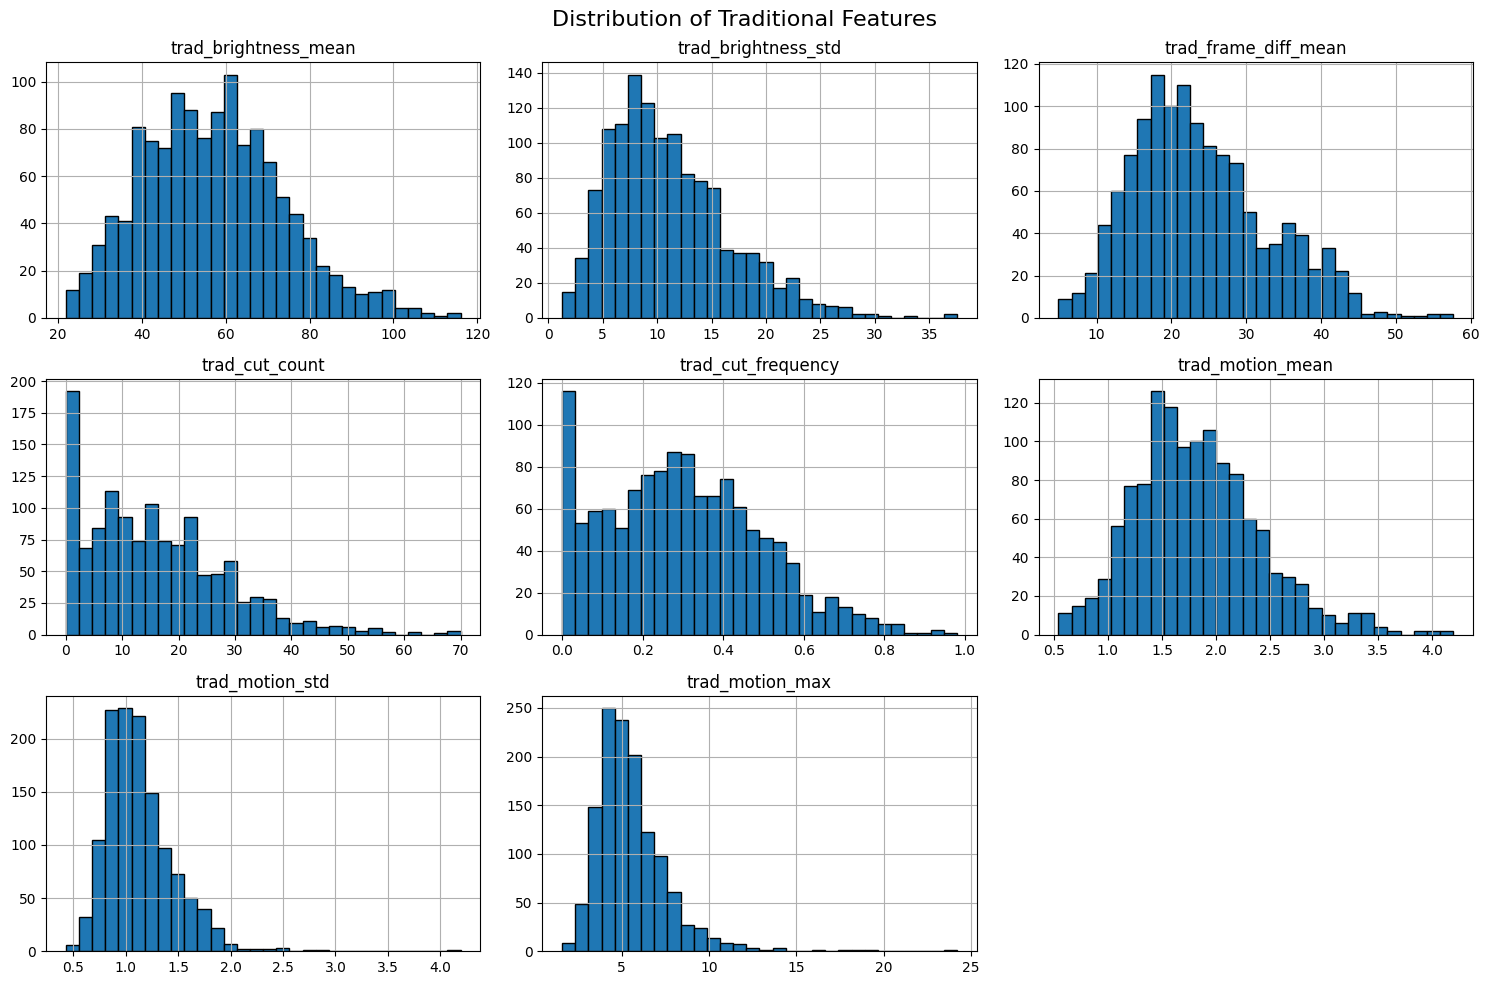

In [ ]:
import matplotlib.pyplot as plt

trad_eda[trad_cols].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Traditional Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

- 컷 빈도는 0 근처에 값이 집중됨
- 실제 편집 특성일 수도 있고 컷 탐지 방식의 한계일 수도..
- 움직임 관련 특징은 오른쪽 꼬리가 긴 분포

In [ ]:
# 컷 빈도가 0인 영상 확인
zero_cut = trad_eda[
    trad_eda['trad_cut_frequency'] == 0
]

print("전체 영상:", len(trad_eda))
print("컷 빈도 0인 영상:", len(zero_cut))
print(
    "비율:",
    round(len(zero_cut) / len(trad_eda) * 100, 2),
    "%"
)

# 컷 빈도 0인 영상의 정보 확인
display(
    zero_cut[
        [
            'video_id',
            'drama_name',
            'channel',
            'duration_sec',
            'trad_cut_count',
            'trad_cut_frequency'
        ]
    ].head(10)
)

전체 영상: 1270
컷 빈도 0인 영상: 95
비율: 7.48 %


,video_id,drama_name,channel,duration_sec,trad_cut_count,trad_cut_frequency
74,5pFQ8aq1haE,안나,K드릭스,49.0,0,0.0
227,MN7_qv3hfJM,이 사랑 통역 되나요?,드라마저장,62.0,0,0.0
229,CW4hqoVM2eM,이 사랑 통역 되나요?,드라마저장,57.0,0,0.0
261,3BzbfJ2zCPk,메이드 인 코리아2,드라마저장,57.0,0,0.0
339,fgXGLTm8R9g,부부의세계,1분드라마모음zip,45.0,0,0.0
418,CcU4H9ZAS1Q,날아올라라나비,1분드라마모음zip,32.0,0,0.0
429,Vkrg0a3rxUo,미스터션샤인,드라마 한입,24.0,0,0.0
430,gbuNu9eoItg,미스터션샤인,드라마 한입,28.0,0,0.0
433,Ru7HaYiaq44,미스터션샤인,드라마 한입,31.0,0,0.0
434,Rr0j7EZaX8M,미스터션샤인,드라마 한입,33.0,0,0.0


- 비율로 따지니까 0 비율이 생각보단 괜찮은듯?
- 95개의 영상이 특정 채널에 집중되어 있는지 확인해야할듯

In [ ]:
# 채널별 전체 영상 수와 컷 빈도 0 비율
channel_zero = (
    trad_eda.assign(
        zero_cut=trad_eda['trad_cut_count'].eq(0)
    )
    .groupby('channel')
    .agg(
        total_videos=('video_id', 'count'),
        zero_cut_videos=('zero_cut', 'sum'),
        zero_cut_rate=('zero_cut', 'mean')
    )
)

channel_zero['zero_cut_rate'] *= 100

# 컷 빈도 0인 비율이 높은 채널 순
channel_zero = channel_zero.sort_values(
    'zero_cut_rate', ascending=False
)

display(channel_zero.round(2))

,total_videos,zero_cut_videos,zero_cut_rate
channel,,,
한드TV,130,59,45.38
드라마 한입,149,26,17.45
K드릭스,31,1,3.23
1분드라마모음zip,121,2,1.65
드라마저장,216,3,1.39
숏까네,485,4,0.82
1분 샤샤샥,61,0,0.00
아워무비,77,0,0.00


- 오.. 컷 빈도가 0인 영상이 특정 채널에 집중되어 있음
- 특정 채널의 영상 특성과 관련 있을지도??

> step8에서 추가 확인

# STEP 4. Traditional 특징과 조회수 성과의 상관관계 분석

In [ ]:
# Traditional 특징과 상대적 조회수 성과의 상관관계
trad_corr = (
    trad_eda[trad_cols + ['z_in_group']]
    .corr(method='spearman')['z_in_group']
    .drop('z_in_group')
    .sort_values(ascending=False)
)

print("Traditional 특징별 Spearman 상관계수")
display(trad_corr.to_frame(name='spearman_r'))

Traditional 특징별 Spearman 상관계수


,spearman_r
trad_cut_count,0.051355
trad_frame_diff_mean,0.040974
trad_cut_frequency,0.040145
trad_brightness_mean,0.025124
trad_motion_max,0.023898
trad_brightness_std,0.023392
trad_motion_mean,0.006159
trad_motion_std,-0.000674


- 8개 특징 모두 z_in_group과의 상관계수가 거의 0
- 컷 전환이 많거나 화면 움직임이 크다고 해서 상대적 조회수 성과가 높아지지는 않음

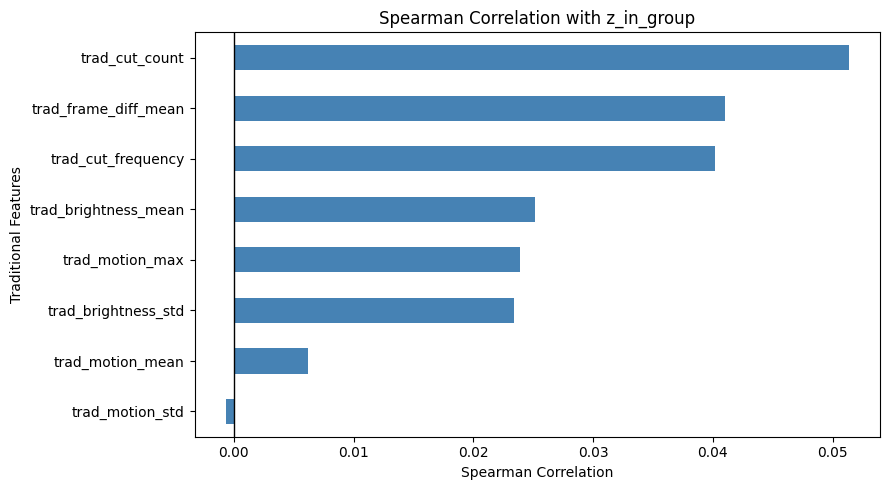

In [ ]:
plt.figure(figsize=(9, 5))

trad_corr.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(0, color='black', linewidth=1)

plt.title(
    'Spearman Correlation with z_in_group'
)
plt.xlabel('Spearman Correlation')
plt.ylabel('Traditional Features')

plt.tight_layout()
plt.show()

# STEP 5. 영상 길이와 Traditional 특징의 상관관계

In [ ]:
# 영상 길이와 Traditional 특징의 Spearman 상관관계
duration_corr = (
    trad_eda[trad_cols + ['duration_sec']]
    .corr(method='spearman')['duration_sec']
    .drop('duration_sec')
    .sort_values(ascending=False)
)

print("영상 길이와 Traditional 특징의 상관관계")
display(duration_corr.to_frame(name='spearman_r'))

영상 길이와 Traditional 특징의 상관관계


,spearman_r
trad_cut_count,0.679269
trad_cut_frequency,0.417827
trad_brightness_std,0.397140
trad_frame_diff_mean,0.391941
trad_brightness_mean,0.247436
trad_motion_max,0.215922
trad_motion_mean,0.181189
trad_motion_std,0.032375


- 컷 개수는 영상 길이의 영향이 큼
- 밝기 변화와 프레임 차이도 길이에 영향을 받긴 함
- 움직임은 근데 대부분의 데이터가 0인 것 같은데 그래서 길이와 관계가 약한것 같기도?

# STEP 6. 영상 길이 통제 전후 상관계수 비교

In [ ]:
# 1. 영상 길이와 특징, 성과를 순위로 변환
rank_df = trad_eda[
    trad_cols + ['duration_sec', 'z_in_group']
].rank()

# 2. 영상 길이의 순위 기준 표준화
x = rank_df['duration_sec']
x_center = x - x.mean()
x_var = (x_center ** 2).sum()

# 3. 성과에서 영상 길이 관계 제거
y = rank_df['z_in_group']
y_resid = y - (
    ((y - y.mean()) * x_center).sum() / x_var
) * x_center

# 4. 특징에서도 영상 길이 관계 제거
results = []

for col in trad_cols:
    f = rank_df[col]

    f_resid = f - (
        ((f - f.mean()) * x_center).sum() / x_var
    ) * x_center

    partial_r = f_resid.corr(y_resid)

    results.append({
        'feature': col,
        'before': trad_corr[col],
        'after_duration_control': partial_r
    })

partial_corr_df = pd.DataFrame(results).set_index('feature')

display(partial_corr_df.round(4))

,before,after_duration_control
feature,,
trad_brightness_mean,0.0251,0.0144
trad_brightness_std,0.0234,0.0059
trad_frame_diff_mean,0.0410,0.0253
trad_cut_count,0.0514,0.0282
trad_cut_frequency,0.0401,0.0234
trad_motion_mean,0.0062,-0.0021
trad_motion_std,-0.0007,-0.0021
trad_motion_max,0.0239,0.0145


# STEP 7. 채널별 Traditional 특징과 성과의 관계

In [ ]:
# 채널별 영상 수 확인
channel_counts = (
    trad_eda['channel']
    .value_counts()
)

print("전체 채널 수:", len(channel_counts))

print("\n채널별 영상 수:")
display(channel_counts.to_frame(name='video_count'))

# 30개 이상 영상이 있는 채널 선택
valid_channels = channel_counts[
    channel_counts >= 30
].index

print("\n분석 대상 채널 수:", len(valid_channels))
print("분석 대상 채널:", valid_channels.tolist())

전체 채널 수: 8

채널별 영상 수:


,video_count
channel,
숏까네,485
드라마저장,216
드라마 한입,149
한드TV,130
1분드라마모음zip,121
아워무비,77
1분 샤샤샥,61
K드릭스,31



분석 대상 채널 수: 8
분석 대상 채널: ['숏까네', '드라마저장', '드라마 한입', '한드TV', '1분드라마모음zip', '아워무비', '1분 샤샤샥', 'K드릭스']


# STEP 8. 채널×드라마별 컷 빈도 확인

In [ ]:
# 채널 × 드라마별 컷 빈도 0 비율
drama_zero = (
    trad_eda.assign(
        zero_cut=trad_eda['trad_cut_count'].eq(0)
    )
    .groupby(['channel', 'drama_name'])
    .agg(
        total_videos=('video_id', 'count'),
        zero_cut_videos=('zero_cut', 'sum'),
        zero_cut_rate=('zero_cut', 'mean'),
        mean_cut_frequency=('trad_cut_frequency', 'mean')
    )
    .reset_index()
)

drama_zero['zero_cut_rate'] *= 100

# 컷 0인 영상이 많았던 두 채널 확인
result = drama_zero[
    drama_zero['channel'].isin(['한드TV', '드라마 한입'])
].sort_values(
    ['channel', 'zero_cut_videos'],
    ascending=[True, False]
)

display(result.round(3))

,channel,drama_name,total_videos,zero_cut_videos,zero_cut_rate,mean_cut_frequency
11,드라마 한입,미스터션샤인,149,26,17.450,0.148
55,한드TV,멜로가체질,25,14,56.000,0.048
57,한드TV,서른아홉,14,10,71.429,0.030
54,한드TV,날아올라라나비,15,9,60.000,0.019
60,한드TV,조선혼담공작소꽃파당,17,7,41.176,0.027
56,한드TV,부부의세계,15,6,40.000,0.050
59,한드TV,이태원클라쓰,19,5,26.316,0.123
61,한드TV,킹더랜드,17,5,29.412,0.067
58,한드TV,아파트,8,3,37.500,0.071


- 오? 한드TV의 높은 0 비율을 특정 드라마 하나가 많이 포함되었기 때문이라고 설명하기는 곤란
- 근데 그라마 한입은 149개 모두 미스터 선샤인이라서 해당 드라마의 영상 특성 때문일수도 있음
- 즉, 채널 효과와 드라마 효과가 서로 겹쳐있는듯

# STEP 9. 채널별 Traditional 특징과 상대적 조회수 성과의 관계 분석

## 채널별 Spearman 상관관계

In [ ]:
# 채널별 Traditional 특징과 z_in_group의 상관관계

channel_corr_results = []

for channel, data in trad_eda.groupby('channel'):

    for feature in trad_cols:

        corr = data[feature].corr(
            data['z_in_group'],
            method='spearman'
        )

        channel_corr_results.append({
            'channel': channel,
            'n_videos': len(data),
            'feature': feature,
            'spearman_r': corr
        })

channel_corr_df = pd.DataFrame(channel_corr_results)

# 채널별 상관관계 표
channel_corr_table = channel_corr_df.pivot(
    index='channel',
    columns='feature',
    values='spearman_r'
)

display(channel_corr_table.round(3))

feature,trad_brightness_mean,trad_brightness_std,trad_cut_count,trad_cut_frequency,trad_frame_diff_mean,trad_motion_max,trad_motion_mean,trad_motion_std
channel,,,,,,,,
1분 샤샤샥,0.138,0.195,0.199,0.084,0.108,-0.020,0.071,0.018
1분드라마모음zip,0.129,0.230,0.253,0.195,0.365,0.349,0.338,0.289
K드릭스,0.110,-0.023,-0.013,0.080,-0.008,0.008,-0.197,0.029
드라마 한입,-0.114,-0.069,0.186,0.203,0.006,-0.126,-0.092,-0.133
드라마저장,0.010,0.006,0.058,0.070,0.067,-0.018,0.068,-0.046
숏까네,0.012,-0.021,-0.004,-0.021,0.014,-0.000,-0.020,-0.015
아워무비,-0.169,0.088,0.331,0.019,-0.155,0.198,-0.263,0.221
한드TV,0.095,0.122,-0.003,0.005,0.191,0.159,0.108,0.088


- 1분드라마모음zip에서는 프레임 차이(ρ=0.365), 최대 움직임(ρ=0.349), 평균 움직임(ρ=0.338)이 상대적 성과와 양의 상관관계를 보임
- 아워무비에서는 컷 개수(ρ=0.331)가 양의 관계를, 평균 움직임(ρ=-0.263)이 음의 관계를 보임

## 컷 빈도와 성과의 관계부터 비교

In [ ]:
# 채널별 컷 빈도와 성과의 관계
cut_channel_corr = channel_corr_df[
    channel_corr_df['feature'] == 'trad_cut_frequency'
].sort_values('spearman_r', ascending=False)

display(
    cut_channel_corr[
        ['channel', 'n_videos', 'spearman_r']
    ].round(3)
)

,channel,n_videos,spearman_r
28,드라마 한입,149,0.203
12,1분드라마모음zip,121,0.195
4,1분 샤샤샥,61,0.084
20,K드릭스,31,0.080
36,드라마저장,216,0.070
52,아워무비,77,0.019
60,한드TV,130,0.005
44,숏까네,485,-0.021


- 전체 데이터: Traditional 특징과 상대적 조회수 성과의 단순 상관관계는 매우 약함
- 영상 길이 통제 후: 상관관계는 여전히 약함
- 채널별 분석: 일부 채널에서는 특정 Traditional 특징과 상대적 성과 사이에 상대적으로 큰 상관관계가 관찰됨

# STEP 10. 업로드 경과일과 Traditional 특징의 상관관계

In [ ]:
# 업로드 경과일과 Traditional 특징의 Spearman 상관계수

days_corr = (
    trad_eda[trad_cols + ['days_since_upload', 'z_in_group']]
    .corr(method='spearman')['days_since_upload']
    .drop('days_since_upload')
    .sort_values(ascending=False)
)

print("업로드 경과일과 Traditional 특징 및 성과의 상관관계")
display(days_corr.to_frame(name='spearman_r').round(4))

업로드 경과일과 Traditional 특징 및 성과의 상관관계


,spearman_r
trad_frame_diff_mean,0.5514
trad_brightness_std,0.4268
trad_motion_mean,0.4040
trad_cut_count,0.3624
trad_cut_frequency,0.3617
trad_brightness_mean,0.2721
trad_motion_max,0.1736
trad_motion_std,0.0715
z_in_group,-0.0181


- 오래전에 업로드된 영상일수록 프레임 간 화면 변화량이 큰 경향
- 근데 오래된 영상과 최근 영상의 편집 방식이나 채널, 드라마 구성이 서로 다르기 때문일 수 있음
- 업로드 경과일과 z_in_group은 거의 관계가 없음 !!

# STEP 11. 그룹 내 업로드 경과일과 상대적 성과

In [ ]:
# 드라마×채널 그룹별 업로드 경과일과 성과의 관계
group_days_corr = (
    trad_eda.groupby('group')
    .apply(
        lambda x: x['days_since_upload'].corr(
            x['z_in_group'],
            method='spearman'
        ),
        include_groups=False
    )
    .dropna()
    .sort_values()
)

print("분석 가능한 그룹 수:", len(group_days_corr))

print("\n그룹별 상관계수 요약:")
display(group_days_corr.describe().round(3))

print("\n가장 음의 관계가 강한 그룹 5개:")
display(group_days_corr.head(5))

print("\n가장 양의 관계가 강한 그룹 5개:")
display(group_days_corr.tail(5))

분석 가능한 그룹 수: 62

그룹별 상관계수 요약:


,0
count,62.000
mean,0.147
std,0.358
min,-0.883
25%,-0.070
50%,0.169
75%,0.378
max,0.927



가장 음의 관계가 강한 그룹 5개:


,0
group,
악인전|숏까네,-0.883333
분리수거|숏까네,-0.771429
미스터션샤인|드라마 한입,-0.466442
슬기로운 의사생활|아워무비,-0.412917
안나|K드릭스,-0.339525



가장 양의 관계가 강한 그룹 5개:


,0
group,
아파트|숏까네,0.625385
나를 충전해줘|드라마저장,0.660606
계시록|숏까네,0.800000
상속자들|1분 샤샤샥,0.900000
"이재, 곧 죽습니다|1분 샤샤샥",0.927273


- 전체 데이터의 상관계수는 거의 0이었는데, 그룹별로 분석하니까 상관관계가 강한 그룹이 존재

# STEP 12. 그룹·영상 길이·업로드 경과일 통제

In [ ]:
import numpy as np

# 분석 변수
control_cols = [
    'duration_sec',
    'days_since_upload'
]

all_cols = trad_cols + control_cols + ['z_in_group']

# 그룹 내 평균 제거
within_df = trad_eda[all_cols] - (
    trad_eda.groupby('group')[all_cols].transform('mean')
)

# 통제변수 행렬
X = within_df[control_cols].to_numpy()

# 통제변수의 영향을 제거하는 함수
def residualize(y, X):
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    return y - X @ coef

# 성과 변수 잔차
y_resid = residualize(
    within_df['z_in_group'].to_numpy(), X
)

results = []

for feature in trad_cols:
    feature_resid = residualize(
        within_df[feature].to_numpy(), X
    )

    corr = np.corrcoef(
        feature_resid,
        y_resid
    )[0, 1]

    results.append({
        'feature': feature,
        'before': trad_corr[feature],
        'after_controls': corr
    })

control_results = pd.DataFrame(results).set_index('feature')

display(control_results.round(4))

,before,after_controls
feature,,
trad_brightness_mean,0.0251,0.0283
trad_brightness_std,0.0234,0.0163
trad_frame_diff_mean,0.0410,0.0766
trad_cut_count,0.0514,0.0480
trad_cut_frequency,0.0401,0.0565
trad_motion_mean,0.0062,0.0342
trad_motion_std,-0.0007,0.0279
trad_motion_max,0.0239,0.0675


- 통제 후 일부 특징의 상관계수가 커졌지만, 여전히 전체적으로 관계가 약함

**Traditional 특징 EDA 결과 요약**

총 1,270개 영상에서 추출한 Traditional 특징 8개와 드라마×채널 그룹 내 상대적 조회수 성과(`z_in_group`)의 관계를 분석했습니다.

전체 Spearman 상관분석에서는 모든 특징의 상관계수 절댓값이 약 0.052 이하로 매우 약한 관계를 보였습니다.

반면 영상 길이와는 컷 개수(ρ=0.679), 컷 빈도(ρ=0.418)가 비교적 높은 양의 상관관계를 보였고, 업로드 경과일과는 프레임 차이(ρ=0.551), 평균 움직임(ρ=0.404)이 관련되어 있었습니다.

채널별 분석에서는 일부 차이가 관찰되었습니다. 특히 1분드라마모음zip에서 프레임 차이(ρ=0.365), 평균 움직임(ρ=0.338)이 상대적 성과와 양의 상관관계를 보였습니다.

드라마×채널 그룹, 영상 길이, 업로드 경과일을 고려한 순위 기반 부분상관분석에서도 모든 특징의 상관계수 절댓값이 0.10 미만이었습니다.

따라서 Traditional 특징은 상대적 조회수 성과와 강한 개별 단조 관계를 보이지 않았으며, 향후 모델링에서 비선형 관계와 다른 특징 유형과의 결합 효과를 확인할 필요가 있습니다.

추가로 컷 빈도 0인 영상은 95개(7.48%)였으며, 일부 채널에 집중되어 있어 컷 탐지 방식의 한계 가능성을 분석 시 고려해야 합니다.